# 09 — Backtest 004: Rompimento da faixa asiática na abertura de Londres (EURUSD M15 · H1, filtro H4)

**Hipótese:** durante a madrugada (sessão asiática) o EURUSD anda pouco e forma uma **faixa**. Quando Londres abre,
entra volume e o preço **rompe** um dos lados da faixa e segue naquela direção. É a lógica oposta à do 003
(Bollinger), que apostava na **volta** à média.

**Regras:**

| Item | Regra |
|---|---|
| Faixa asiática | Máxima e mínima entre **00h e 10h** do servidor (ou 03h–10h, como variação) |
| Abertura de Londres | **10h do servidor** = 8h em Londres, o ano todo (os dois mudam de horário juntos) |
| Entrada | **Ordem stop** 1 pip acima da máxima / abaixo da mínima (o clássico) **ou** só quando uma barra **fecha** fora da faixa |
| Janela de entrada | Das 10h às 15h do servidor (manhã de Londres, antes de Nova York). **No máximo 1 operação por dia** |
| Stop | **Lado oposto** da faixa ou **meio** da faixa |
| Alvo | 1 R, 1,5 R, 2 R ou **sem alvo** (sai no fim do dia) |
| Zerar | Sempre às 23h do servidor (day trade, sem swap) |
| Filtros (variações) | Só dias de **faixa estreita** (abaixo da mediana de 20 dias); só a favor da **tendência do H4** |

**Custos:** spread de cada barra (com alargamento na virada do dia), slippage de 2 pontos por lado, comissão como
sensibilidade. **Validação:** a regra clássica primeiro, depois uma grade escolhida **só no treino**, teste fora da
amostra, comparação com **direção aleatória** e os critérios do laboratório.

> Sem look-ahead: a faixa só é usada depois das 10h, quando já está completa. A ordem stop é preenchida no nível
> (ou na abertura, se o preço abrir além dele). Quando a barra de entrada também toca o stop, contamos o stop.

## 1. Configuração

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numba import njit

# ---------------- setup ----------------
BACKTEST_ID = "004"
SIMBOLO = "EURUSD"
TFS = ["M15", "H1"]
DATA_INICIO = "2010-01-01"

ABERTURA_LONDRES = 10  # hora do servidor XM
CORTE_ENTRADA = 15  # última hora para entrar (antes de Nova York)
BUFFER_PIPS = 1.0
MEDIANA_DIAS = 20  # para definir "faixa estreita"
EMA_TEND, EMA_MEDIA, INCLINACAO_BARRAS = 200, 50, 20  # tendência do H4 (mesma régua do 002)

# ---------------- regra clássica ----------------
PADRAO = {"inicio_faixa": 0, "entrada": "ordem stop", "stop": "lado oposto", "alvo_r": 0.0,
          "faixa": "todas", "tendencia": "sem filtro"}

# ---------------- grade (testada só no treino) ----------------
GRADE_INICIO = [0, 3]
GRADE_ENTRADA = ["ordem stop", "fechamento"]
GRADE_STOP = ["lado oposto", "meio"]
GRADE_ALVO = [1.0, 1.5, 2.0, 0.0]  # 0 = sem alvo, sai no fim do dia
GRADE_FAIXA = ["todas", "estreita"]
GRADE_TEND = ["sem filtro", "a favor do H4"]

# ---------------- day trade e custos ----------------
HORA_ZERAR = 23
HORAS_VIRADA = (22, 23, 0)
MULT_SPREAD_VIRADA = 1.5
SLIPPAGE_PONTOS = 2
COMISSAO_USD_LOTE = 0.0
RISCO_POR_TRADE = 0.01

# ---------------- validação ----------------
INICIO_OOS = {"M15": "2025-01-01", "H1": "2021-01-01"}
MIN_TRADES_TREINO = 100
N_SIM, SEED = 300, 42
MIN_TRADES_SEMANA, MAX_INTERVALO_P90 = 2.0, 5

RAIZ = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "dados" / "xm").is_dir()), None)
if RAIZ is None:
    raise FileNotFoundError(f"Não encontrei a pasta dados/xm a partir de {Path.cwd()}")
PASTA_DADOS = RAIZ / "dados" / "xm"
sys.path.insert(0, str(RAIZ / "src"))
from lhsquant.estilo import aplicar_estilo, CORES

aplicar_estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
info = pd.read_parquet(PASTA_DADOS / "info_simbolos.parquet")
info = info[info["simbolo"] == SIMBOLO].sort_values("data").iloc[-1]
PONTO, CONTRATO = float(info["ponto"]), float(info["contrato"])
SLIP = SLIPPAGE_PONTOS * PONTO
BUF = BUFFER_PIPS * 10 * PONTO
print(f"{SIMBOLO}: Londres abre às {ABERTURA_LONDRES}h do servidor | entrada até {CORTE_ENTRADA}h | zera às {HORA_ZERAR}h | "
      f"OOS: {INICIO_OOS}")

EURUSD: Londres abre às 10h do servidor | entrada até 15h | zera às 23h | OOS: {'M15': '2025-01-01', 'H1': '2021-01-01'}


## 2. Dados, faixa asiática e filtros (sem look-ahead)

Para cada dia (data do servidor):
- **Faixa:** máxima e mínima das barras que **abrem** entre o início da faixa e as 10h. Dias com faixa incompleta
  (feriados, dados faltando) ficam de fora.
- **Faixa estreita:** largura menor que a **mediana dos 20 dias anteriores** (só dias passados, por isso o `shift(1)`).
- **Tendência do H4:** a mesma régua do 002 (preço e EMA 50 acima da EMA 200, com a EMA 200 subindo há 20 barras),
  usando **só a última barra de H4 já fechada** na hora do sinal.

In [2]:
DUR = {"M15": pd.Timedelta(minutes=15), "H1": pd.Timedelta(hours=1), "H4": pd.Timedelta(hours=4)}
BARRAS_HORA = {"M15": 4, "H1": 1}


def carregar(tf):
    return pd.read_parquet(PASTA_DADOS / SIMBOLO / f"{tf}.parquet").sort_index().loc[DATA_INICIO:]


def ema(s, n):
    return s.ewm(span=n, adjust=False).mean()


H4 = carregar("H4")
c4 = H4["fechamento"]
et, e50 = ema(c4, EMA_TEND), ema(c4, EMA_MEDIA)
TEND_H4 = pd.Series(np.select([(c4 > et) & (e50 > et) & (et > et.shift(INCLINACAO_BARRAS)),
                               (c4 < et) & (e50 < et) & (et < et.shift(INCLINACAO_BARRAS))], [1, -1], 0), H4.index)


def preparar(tf):
    df = carregar(tf)
    idx = df.index
    fecha = idx + DUR[tf]
    dia = idx.normalize()
    ultimo_do_dia = np.append(dia[1:] != dia[:-1], True)
    mult = np.where(np.isin(idx.hour, HORAS_VIRADA), MULT_SPREAD_VIRADA, 1.0)
    # tendência do H4 disponível no FECHAMENTO de cada barra (só H4 já fechado)
    t4 = pd.DataFrame({"t": TEND_H4.index + DUR["H4"], "v": TEND_H4.to_numpy()})
    tend = pd.merge_asof(pd.DataFrame({"t": fecha}), t4, on="t", direction="backward")["v"].fillna(0).to_numpy(np.int64)
    a = {"idx": idx, "df": df, "dia": dia,
         "o": df["abertura"].to_numpy(float), "h": df["maxima"].to_numpy(float),
         "l": df["minima"].to_numpy(float), "c": df["fechamento"].to_numpy(float),
         "spr": df["spread"].to_numpy(float) * PONTO * mult,
         "janela": np.asarray((idx.hour >= ABERTURA_LONDRES) & (idx.hour < CORTE_ENTRADA)),
         "zerar": np.asarray((fecha.hour >= HORA_ZERAR) | (fecha.hour == 0) | ultimo_do_dia),
         "tend": tend,
         "dia_id": pd.factorize(dia)[0].astype(np.int64)}
    a["faixas"] = {ini: faixa(a, tf, ini) for ini in GRADE_INICIO}
    return a


def faixa(a, tf, ini):
    # máxima/mínima da faixa por dia, mapeadas para cada barra; NaN em dias incompletos
    df, h = a["df"], a["idx"].hour
    dentro = (h >= ini) & (h < ABERTURA_LONDRES)
    g = df[dentro].groupby(a["dia"][dentro]).agg(hi=("maxima", "max"), lo=("minima", "min"), n=("maxima", "size"))
    g = g[g["n"] >= 0.8 * (ABERTURA_LONDRES - ini) * BARRAS_HORA[tf]]
    g["largura"] = g["hi"] - g["lo"]
    g["estreita"] = g["largura"] < g["largura"].rolling(MEDIANA_DIAS).median().shift(1)
    m = g.reindex(a["dia"])
    return {"hi": m["hi"].to_numpy(float), "lo": m["lo"].to_numpy(float),
            "estreita": m["estreita"].fillna(False).to_numpy(bool), "dias": g}


D = {tf: preparar(tf) for tf in TFS}
for tf, a in D.items():
    for ini in GRADE_INICIO:
        g = a["faixas"][ini]["dias"]
        print(f"{tf:>3} faixa {ini:02d}h–{ABERTURA_LONDRES}h: {len(g):>5} dias | largura mediana {g['largura'].median() / 0.0001:.0f} pips "
              f"| p10–p90 {g['largura'].quantile(0.1) / 0.0001:.0f}–{g['largura'].quantile(0.9) / 0.0001:.0f} pips")

M15 faixa 00h–10h:  1040 dias | largura mediana 28 pips | p10–p90 16–52 pips
M15 faixa 03h–10h:  1041 dias | largura mediana 25 pips | p10–p90 14–45 pips
 H1 faixa 00h–10h:  4166 dias | largura mediana 33 pips | p10–p90 18–71 pips
 H1 faixa 03h–10h:  4165 dias | largura mediana 30 pips | p10–p90 16–61 pips


## 3. O motor (barra a barra, com numba)

Para cada dia, a partir das 10h:
1. **Ordem stop:** se a máxima da barra alcança a máxima da faixa + 1 pip, compra nesse nível (ou na abertura, se
   abriu acima). Igual para a venda na mínima. Se a mesma barra rompe **os dois lados**, o dia é descartado (não dá para
   saber qual veio primeiro).
2. **Fechamento:** se a barra **fecha** fora da faixa, entra na abertura da barra seguinte.
3. Com posição: **stop primeiro** (conservador), depois **alvo**; no fechamento, **zera** às 23h.

O parâmetro `inv` serve para o **teste do acaso**: quando é −1, a operação é feita **na direção contrária** do
rompimento, com o mesmo preço, a mesma distância de stop e o mesmo alvo.

In [3]:
@njit(cache=True)
def motor(o, h, l, c, spr, hi, lo, janela, zerar, pode_c, pode_v, dia_id, inv,
          modo, stop_meio, alvo_r, buf, slip, comis):
    n = len(c)
    cap = dia_id[-1] + 10
    ent = np.empty(cap, np.int64)
    sai = np.empty(cap, np.int64)
    dire = np.empty(cap, np.int64)
    mot = np.empty(cap, np.int64)
    rl = np.empty(cap)
    rb = np.empty(cap)
    nt, pos, dia_feito, pend = 0, 0, -1, 0
    stop, alvo, e_l, e_b, risco = 0.0, 0.0, 0.0, 0.0, 1.0
    for t in range(1, n):
        d_hoje = dia_id[t]
        # -- entrada pendente do modo "fechamento" (sinal na barra anterior)
        if pend != 0 and pos == 0:
            d, pend = pend, 0
            if dia_id[t] == dia_id[t - 1] and not zerar[t]:
                px_b = o[t]
                dist = (o[t] - (lo[t] - buf if not stop_meio else (hi[t] + lo[t]) / 2)) if d == 1 else \
                       ((hi[t] + buf if not stop_meio else (hi[t] + lo[t]) / 2) - o[t])
                if dist > 0:
                    if inv[t] == -1:
                        d = -d
                    e_b = px_b
                    e_l = px_b + spr[t] + slip if d == 1 else px_b - slip
                    stop = e_l - d * dist
                    risco = dist
                    alvo = e_l + d * alvo_r * risco
                    pos = d
                    ent[nt], dire[nt] = t, d
        if pos != 0:
            px, m = 0.0, 0
            if pos == 1:
                if l[t] <= stop:
                    px, m = min(o[t], stop), 1
                elif alvo_r > 0 and h[t] >= alvo and ent[nt] != t:
                    px, m = max(o[t], alvo), 2
            else:
                if h[t] + spr[t] >= stop:
                    px, m = max(o[t] + spr[t], stop), 1
                elif alvo_r > 0 and l[t] + spr[t] <= alvo and ent[nt] != t:
                    px, m = min(o[t] + spr[t], alvo), 2
            if m == 0 and (zerar[t] or t == n - 1):
                m = 3 if zerar[t] else 4
                px = c[t] if pos == 1 else c[t] + spr[t]
            if m != 0:
                if pos == 1:
                    x_b, x_l = px, px - slip
                else:
                    x_b, x_l = px - spr[t], px + slip
                rb[nt] = pos * (x_b - e_b) / risco
                rl[nt] = (pos * (x_l - e_l) - comis) / risco
                sai[nt], mot[nt] = t, m
                nt += 1
                pos = 0
            continue
        if dia_feito == d_hoje or not janela[t] or zerar[t] or np.isnan(hi[t]):
            continue
        nivel_c, nivel_v = hi[t] + buf, lo[t] - buf
        if modo == 1:  # fechamento fora da faixa -> entra na próxima barra
            if c[t] > nivel_c and pode_c[t]:
                pend, dia_feito = 1, d_hoje
            elif c[t] < nivel_v and pode_v[t]:
                pend, dia_feito = -1, d_hoje
            continue
        rompe_c = h[t] + spr[t] >= nivel_c
        rompe_v = l[t] <= nivel_v
        if rompe_c and rompe_v:
            dia_feito = d_hoje  # ambíguo: descarta o dia
            continue
        if not (rompe_c or rompe_v):
            continue
        dia_feito = d_hoje
        d = 1 if rompe_c else -1
        if (d == 1 and not pode_c[t]) or (d == -1 and not pode_v[t]):
            continue
        meio = (hi[t] + lo[t]) / 2
        if d == 1:
            px_l = max(o[t] + spr[t], nivel_c)
            s0 = meio if stop_meio else nivel_v
            dist = px_l - s0
            px_b = px_l - spr[t]
        else:
            px_b = min(o[t], nivel_v)
            s0 = meio if stop_meio else nivel_c
            dist = s0 - (px_b + spr[t])
        if dist <= 0:
            continue
        if inv[t] == -1:
            d = -d
        e_b = px_b
        e_l = px_b + spr[t] + slip if d == 1 else px_b - slip
        stop = e_l - d * dist
        risco = dist
        alvo = e_l + d * alvo_r * risco
        pos = d
        ent[nt], dire[nt] = t, d
        # a barra de entrada também tocou o stop? conta o stop (conservador)
        if (d == 1 and l[t] <= stop) or (d == -1 and h[t] + spr[t] >= stop):
            x_b = stop if d == 1 else stop - spr[t]
            x_l = stop - slip if d == 1 else stop + slip
            rb[nt] = d * (x_b - e_b) / risco
            rl[nt] = (d * (x_l - e_l) - comis) / risco
            sai[nt], mot[nt] = t, 1
            nt += 1
            pos = 0
    return ent[:nt], sai[:nt], dire[:nt], mot[:nt], rl[:nt], rb[:nt]


MOTIVOS = np.array(["", "stop", "alvo", "fim do dia", "fim dos dados"])


def rodar(tf, inicio_faixa, entrada, stop, alvo_r, faixa, tendencia, comissao=COMISSAO_USD_LOTE, inv=None):
    a = D[tf]
    fx = a["faixas"][inicio_faixa]
    ok = fx["estreita"] if faixa == "estreita" else np.ones(len(a["c"]), bool)
    pode_c = ok & ((a["tend"] == 1) if tendencia == "a favor do H4" else True)
    pode_v = ok & ((a["tend"] == -1) if tendencia == "a favor do H4" else True)
    inv = np.ones(len(a["c"]), np.int64) if inv is None else inv
    ent, sai, d, m, rl, rb = motor(a["o"], a["h"], a["l"], a["c"], a["spr"], fx["hi"], fx["lo"], a["janela"],
                                   a["zerar"], np.asarray(pode_c), np.asarray(pode_v), a["dia_id"], inv,
                                   1 if entrada == "fechamento" else 0, stop == "meio", float(alvo_r),
                                   BUF, SLIP, comissao / CONTRATO)
    return pd.DataFrame({"entrada": a["idx"][ent], "saida": a["idx"][sai], "direcao": d,
                         "motivo": MOTIVOS[m], "R": rl, "R_bruto": rb})

### Métricas (as mesmas dos backtests anteriores)

In [4]:
def frequencia(tr, ini, fim):
    dias = pd.bdate_range(ini.normalize(), fim.normalize())
    d_ent = np.sort(tr["entrada"].dt.normalize().unique().to_numpy().astype("datetime64[D]"))
    pontos = np.concatenate([[np.datetime64(ini.normalize(), "D")], d_ent, [np.datetime64(fim.normalize(), "D")]])
    gaps = np.busday_count(pontos[:-1], pontos[1:])
    gaps = gaps[gaps > 0] if (gaps > 0).any() else np.array([len(dias)])
    return {"Trades/semana": len(tr) / (len(dias) / 5),
            "Intervalo p90 (dias úteis)": float(np.percentile(gaps, 90))}


def metricas(tr, ini, fim):
    tr = tr[(tr["entrada"] >= ini) & (tr["entrada"] <= fim)]
    if len(tr) == 0:
        return pd.Series({"Nº trades": 0})
    r = tr["R"]
    g, p = r[r > 0], r[r <= 0]
    cap = (1 + RISCO_POR_TRADE * r).cumprod()
    dias = pd.bdate_range(ini.normalize(), fim.normalize())
    ret_d = (tr.groupby(tr["saida"].dt.normalize())["R"].sum() * RISCO_POR_TRADE).reindex(dias, fill_value=0.0)
    neg = np.minimum(ret_d, 0)
    return pd.Series({
        "Nº trades": len(tr),
        "Win rate %": len(g) / len(tr) * 100,
        "Payoff": g.mean() / abs(p.mean()) if len(p) and len(g) else np.nan,
        "Expectativa R sem custos": tr["R_bruto"].mean(),
        "Expectativa R": r.mean(),
        "Fator de lucro": g.sum() / abs(p.sum()) if len(p) else np.nan,
        "Retorno % (1% risco)": (cap.iloc[-1] - 1) * 100,
        "Máx. drawdown %": (cap / cap.cummax() - 1).min() * 100,
        "Sharpe": ret_d.mean() / ret_d.std() * np.sqrt(252) if ret_d.std() > 0 else np.nan,
        "Sortino": ret_d.mean() / np.sqrt((neg ** 2).mean()) * np.sqrt(252) if (neg < 0).any() else np.nan,
        **frequencia(tr, ini, fim),
    })


def dd_ano(r):
    cap = (1 + RISCO_POR_TRADE * r).cumprod()
    return (cap / cap.cummax() - 1).min() * 100


def periodos(tf):
    a = D[tf]
    oos = pd.Timestamp(INICIO_OOS[tf])
    return {"treino": (a["idx"][0], oos - pd.Timedelta(seconds=1)), "fora": (oos, a["idx"][-1])}

## 4. A regra clássica, sem otimização

Faixa das 00h às 10h, ordem stop 1 pip além da faixa, stop no lado oposto, sem alvo (sai no fim do dia), sem filtros.

In [5]:
linhas = {}
for tf in TFS:
    tr = rodar(tf, **PADRAO)
    for per, (ini, fim) in periodos(tf).items():
        linhas[(tf, per)] = metricas(tr, ini, fim)
RES_PADRAO = pd.DataFrame(linhas)
display(RES_PADRAO.loc[["Nº trades", "Win rate %", "Payoff", "Expectativa R sem custos", "Expectativa R",
                        "Fator de lucro", "Máx. drawdown %", "Sharpe", "Trades/semana"]].round(3))

M15                H1          
                          treino    fora    treino      fora
Nº trades                532.000 396.000 2,364.000 1,332.000
Win rate %                40.977  41.919    42.090    43.168
Payoff                     1.326   1.119     1.335     1.318
Expectativa R sem custos   0.048  -0.005     0.042     0.083
Expectativa R             -0.040  -0.091    -0.014     0.000
Fator de lucro             0.920   0.808     0.971     1.001
Máx. drawdown %          -30.671 -36.029   -67.890   -43.146
Sharpe                    -0.497  -1.251    -0.172     0.005
Trades/semana              4.555   4.204     4.384     4.399

**Como ler:** se a "Expectativa R sem custos" já é negativa, o rompimento da Ásia não tem vantagem bruta; se é positiva
e a líquida negativa, os custos é que matam (como no 002.1 e no 003).

## 5. Grade de variações (só no treino)

128 combinações por tempo gráfico: início da faixa (00h ou 03h) × entrada (ordem stop ou fechamento) × stop (lado oposto
ou meio) × alvo (1 R, 1,5 R, 2 R ou sem alvo) × faixa (todas ou só estreitas) × tendência do H4 (sem filtro ou a favor).
A melhor é escolhida **só pelo treino**, com pelo menos 100 operações.

In [6]:
grade = []
for tf in TFS:
    (ti, tfim), (oi, ofim) = periodos(tf).values()
    for ini in GRADE_INICIO:
        for en in GRADE_ENTRADA:
            for st in GRADE_STOP:
                for al in GRADE_ALVO:
                    for fx in GRADE_FAIXA:
                        for td in GRADE_TEND:
                            cfg = dict(inicio_faixa=ini, entrada=en, stop=st, alvo_r=al, faixa=fx, tendencia=td)
                            tr = rodar(tf, **cfg)
                            mt, mo = metricas(tr, ti, tfim), metricas(tr, oi, ofim)
                            grade.append({"tf": tf, **cfg,
                                          "trades_treino": mt.get("Nº trades", 0), "exp_treino": mt.get("Expectativa R", np.nan),
                                          "exp_bruta_treino": mt.get("Expectativa R sem custos", np.nan),
                                          "trades_fora": mo.get("Nº trades", 0), "exp_fora": mo.get("Expectativa R", np.nan)})
GRADE = pd.DataFrame(grade)

ESCOLHA = {}
for tf in TFS:
    g = GRADE[(GRADE["tf"] == tf) & (GRADE["trades_treino"] >= MIN_TRADES_TREINO)]
    melhor = g.sort_values("exp_treino", ascending=False).iloc[0]
    ESCOLHA[tf] = {"inicio_faixa": int(melhor["inicio_faixa"]), "entrada": melhor["entrada"], "stop": melhor["stop"],
                   "alvo_r": float(melhor["alvo_r"]), "faixa": melhor["faixa"], "tendencia": melhor["tendencia"]}
    print(f"\n{tf}: {len(g)} combinações válidas | positivas no treino (líquido): {(g['exp_treino'] > 0).sum()} | "
          f"positivas sem custos: {(g['exp_bruta_treino'] > 0).sum()}")
    display(g.sort_values("exp_treino", ascending=False).head(5).drop(columns="tf").round(3).reset_index(drop=True))
    print("Média por variação (treino × fora):")
    for col in ["entrada", "stop", "alvo_r", "faixa", "tendencia"]:
        display(g.groupby(col)[["exp_treino", "exp_fora"]].mean().round(3))


M15: 128 combinações válidas | positivas no treino (líquido): 28 | positivas sem custos: 87


,inicio_faixa,entrada,stop,alvo_r,faixa,tendencia,trades_treino,exp_treino,exp_bruta_treino,trades_fora,exp_fora
0,3,fechamento,lado oposto,0.000,estreita,a favor do H4,129.000,0.194,0.300,108.000,-0.061
1,0,fechamento,lado oposto,0.000,estreita,a favor do H4,124.000,0.118,0.214,98.000,-0.090
2,3,ordem stop,lado oposto,0.000,estreita,a favor do H4,132.000,0.111,0.233,103.000,-0.036
3,3,fechamento,lado oposto,2.000,estreita,a favor do H4,129.000,0.106,0.210,108.000,-0.065
4,3,fechamento,lado oposto,1.500,estreita,a favor do H4,129.000,0.093,0.195,108.000,-0.055


Média por variação (treino × fora):


,exp_treino,exp_fora
entrada,,
fechamento,-0.043,-0.078
ordem stop,-0.244,-0.138


,exp_treino,exp_fora
stop,,
lado oposto,-0.005,-0.073
meio,-0.282,-0.144


,exp_treino,exp_fora
alvo_r,,
0.000,-0.119,-0.115
1.000,-0.161,-0.129
1.500,-0.149,-0.091
2.000,-0.145,-0.098


... (6 outputs left out)

,exp_treino,exp_fora
stop,,
lado oposto,-0.037,-0.015
meio,-0.275,-0.311


,exp_treino,exp_fora
alvo_r,,
0.000,-0.151,-0.141
1.000,-0.160,-0.176
1.500,-0.154,-0.169
2.000,-0.158,-0.165


,exp_treino,exp_fora
faixa,,
estreita,-0.175,-0.188
todas,-0.137,-0.138


,exp_treino,exp_fora
tendencia,,
a favor do H4,-0.155,-0.152
sem filtro,-0.157,-0.174


## 6. Fora da amostra e comparação com o acaso

A combinação escolhida no treino roda no período que ela nunca viu. **Teste do acaso:** nos **mesmos dias e
horários** de entrada, a direção é sorteada (cara ou coroa), com a mesma distância de stop e o mesmo alvo. Se o
rompimento não for melhor que isso, a direção do rompimento não carrega informação.

M15: escolhida no treino → {'inicio_faixa': 3, 'entrada': 'fechamento', 'stop': 'lado oposto', 'alvo_r': 0.0, 'faixa': 'estreita', 'tendencia': 'a favor do H4'}


H1: escolhida no treino → {'inicio_faixa': 3, 'entrada': 'ordem stop', 'stop': 'lado oposto', 'alvo_r': 0.0, 'faixa': 'todas', 'tendencia': 'a favor do H4'}


,M15,H1
Nº trades,108.000,608.000
Win rate %,41.667,42.928
Payoff,1.229,1.425
Expectativa R sem custos,0.037,0.130
Expectativa R,-0.061,0.037
Fator de lucro,0.878,1.072
Retorno % (1% risco),-7.090,18.388
Máx. drawdown %,-19.465,-24.092
Sharpe,-0.384,0.270
Sortino,-0.669,0.529


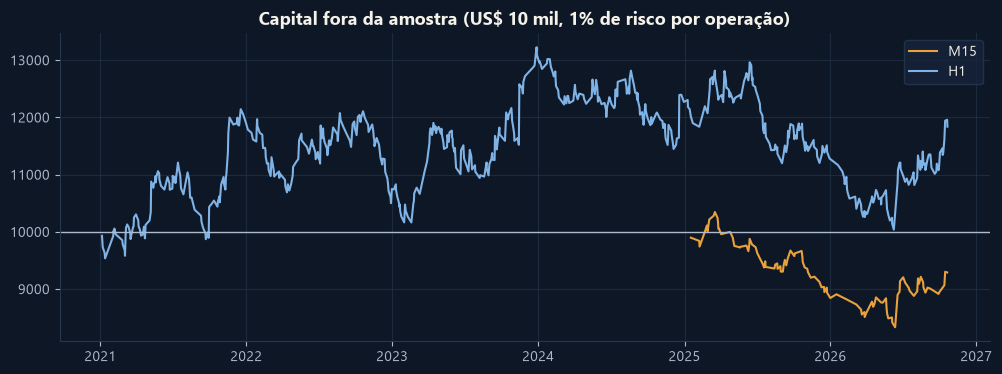


M15 — fora da amostra por motivo, lado, ano e dia da semana:


,trades,R médio,total R
motivo,,,
fim do dia,60,0.697,41.823
stop,48,-1.008,-48.403


,trades,R médio,total R
lado,,,
compra,69,-0.035,-2.394
venda,39,-0.107,-4.186


,trades,R médio,total R,máx. DD %
ano,,,,
2025,62,-0.194,-12.000,-14.527
2026,46,0.118,5.420,-6.463


,trades,R médio,total R
dia_semana,,,
Friday,22,-0.128,-2.806
Monday,27,0.283,7.643
Thursday,20,-0.334,-6.672
Tuesday,18,-0.311,-5.596
Wednesday,21,0.041,0.853



H1 — fora da amostra por motivo, lado, ano e dia da semana:


,trades,R médio,total R
motivo,,,
fim do dia,324,0.954,309.039
stop,284,-1.009,-286.427


,trades,R médio,total R
lado,,,
compra,285,-0.029,-8.273
venda,323,0.096,30.885


,trades,R médio,total R,máx. DD %
ano,,,,
2021,105,0.178,18.648,-11.940
2022,108,-0.087,-9.370,-13.261
2023,103,0.205,21.134,-8.084
2024,101,-0.057,-5.743,-12.061
2025,105,-0.074,-7.740,-13.615
2026,86,0.066,5.683,-10.105


,trades,R médio,total R
dia_semana,,,
Friday,109,-0.010,-1.087
Monday,124,-0.027,-3.299
Thursday,129,0.131,16.907
Tuesday,118,-0.007,-0.848
Wednesday,128,0.085,10.940


In [7]:
rng = np.random.default_rng(SEED)
OOS, TR_OOS, P_VALOR = {}, {}, {}
for tf in TFS:
    oi, ofim = periodos(tf)["fora"]
    cfg = ESCOLHA[tf]
    tr = rodar(tf, **cfg)
    TR_OOS[tf] = tr[tr["entrada"] >= oi]
    m = metricas(tr, oi, ofim)
    n = len(D[tf]["c"])
    sims = np.array([metricas(rodar(tf, inv=rng.choice(np.array([1, -1], np.int64), n), **cfg), oi, ofim)["Expectativa R"]
                     for _ in range(N_SIM)])
    P_VALOR[tf] = float(np.mean(sims >= m["Expectativa R"]))
    m["Aleatório: expectativa R"] = sims.mean()
    m["p-valor vs aleatório"] = P_VALOR[tf]
    m["Com comissão US$7: expectativa R"] = metricas(rodar(tf, comissao=7.0, **cfg), oi, ofim)["Expectativa R"]
    OOS[tf] = m
    print(f"{tf}: escolhida no treino → {cfg}")
RES_OOS = pd.DataFrame(OOS)
display(RES_OOS.round(3))

fig, ax = plt.subplots(figsize=(12, 4))
for tf, cor in zip(TFS, [CORES["primaria"], CORES["secundaria"]]):
    t_ = TR_OOS[tf].sort_values("saida")
    ax.plot(t_["saida"], 10_000 * (1 + RISCO_POR_TRADE * t_["R"]).cumprod(), color=cor, label=tf)
ax.axhline(10_000, color=CORES["texto_suave"], lw=1)
ax.set_title("Capital fora da amostra (US$ 10 mil, 1% de risco por operação)")
ax.legend()
plt.show()

for tf in TFS:
    t_ = TR_OOS[tf].assign(ano=TR_OOS[tf]["entrada"].dt.year, lado=np.where(TR_OOS[tf]["direcao"] == 1, "compra", "venda"),
                           dia_semana=TR_OOS[tf]["entrada"].dt.day_name())
    print(f"\n{tf} — fora da amostra por motivo, lado, ano e dia da semana:")
    for col in ["motivo", "lado", "ano", "dia_semana"]:
        q = t_.groupby(col)["R"].agg(["count", "mean", "sum"]).rename(columns={"count": "trades", "mean": "R médio", "sum": "total R"})
        if col == "ano":
            q["máx. DD %"] = t_.groupby(col)["R"].apply(dd_ano)
        display(q.round(3))

## 7. A regra clássica fora da amostra (sem escolha nenhuma)

Para não depender só da otimização: a regra clássica, que não foi escolhida por ninguém, no mesmo período fora da
amostra e contra o mesmo teste do acaso.

In [8]:
cls = {}
for tf in TFS:
    oi, ofim = periodos(tf)["fora"]
    m = metricas(rodar(tf, **PADRAO), oi, ofim)
    n = len(D[tf]["c"])
    sims = np.array([metricas(rodar(tf, inv=rng.choice(np.array([1, -1], np.int64), n), **PADRAO), oi, ofim)["Expectativa R"]
                     for _ in range(N_SIM)])
    cls[tf] = {"Nº trades": m["Nº trades"], "Expectativa R sem custos": m["Expectativa R sem custos"],
               "Expectativa R": m["Expectativa R"], "Fator de lucro": m["Fator de lucro"],
               "Aleatório: expectativa R": sims.mean(), "p-valor vs aleatório": float(np.mean(sims >= m["Expectativa R"]))}
display(pd.DataFrame(cls).round(3))

,M15,H1
Nº trades,396.000,"1,332.000"
Expectativa R sem custos,-0.005,0.083
Expectativa R,-0.091,0.000
Fator de lucro,0.808,1.001
Aleatório: expectativa R,-0.083,-0.080
p-valor vs aleatório,0.540,0.007


## 8. Veredito

Os mesmos critérios dos backtests anteriores (o PBO não é calculado neste teste; a escolha foi feita só no treino),
aplicados ao **melhor tempo gráfico fora da amostra**.

In [9]:
MELHOR_TF = max(TFS, key=lambda tf: OOS[tf]["Expectativa R"])
m = OOS[MELHOR_TF]
dd_anos = TR_OOS[MELHOR_TF].groupby(TR_OOS[MELHOR_TF]["entrada"].dt.year)["R"].apply(dd_ano)
criterios = pd.DataFrame([
    ("≥ 100 operações fora da amostra", f"{m['Nº trades']:.0f}", m["Nº trades"] >= 100),
    ("Expectativa > 0 R (líquida)", f"{m['Expectativa R']:+.3f}", m["Expectativa R"] > 0),
    ("Fator de lucro > 1,2", f"{m['Fator de lucro']:.2f}", m["Fator de lucro"] > 1.2),
    ("Melhor que aleatório (p < 0,05)", f"p = {P_VALOR[MELHOR_TF]:.3f}", P_VALOR[MELHOR_TF] < 0.05),
    ("Nenhum ano com DD > 20%", f"pior {dd_anos.min():.1f}%", dd_anos.min() > -20),
    (f"≥ {MIN_TRADES_SEMANA:g} trades/semana e p90 ≤ {MAX_INTERVALO_P90} dias úteis",
     f"{m['Trades/semana']:.1f}/sem · p90 {m['Intervalo p90 (dias úteis)']:.0f}",
     (m["Trades/semana"] >= MIN_TRADES_SEMANA) & (m["Intervalo p90 (dias úteis)"] <= MAX_INTERVALO_P90)),
], columns=["Critério", "Valor", "Passou"])
criterios["Passou"] = criterios["Passou"].map({True: "✅", False: "❌"})
print(f"Melhor tempo gráfico fora da amostra: {MELHOR_TF} | configuração: {ESCOLHA[MELHOR_TF]}")
display(criterios)
APROVADO = (criterios["Passou"] == "✅").all()
print("VEREDITO:", "✅ APROVADO" if APROVADO else
      f"❌ REPROVADO ({(criterios['Passou'] == '❌').sum()} de {len(criterios)} critérios falharam)")

Melhor tempo gráfico fora da amostra: H1 | configuração: {'inicio_faixa': 3, 'entrada': 'ordem stop', 'stop': 'lado oposto', 'alvo_r': 0.0, 'faixa': 'todas', 'tendencia': 'a favor do H4'}


,Critério,Valor,Passou
0,≥ 100 operações fora da amostra,608,✅
1,Expectativa > 0 R (líquida),+0.037,✅
2,"Fator de lucro > 1,2",1.07,❌
3,"Melhor que aleatório (p < 0,05)",p = 0.017,✅
4,Nenhum ano com DD > 20%,pior -13.6%,✅
5,≥ 2 trades/semana e p90 ≤ 5 dias úteis,2.0/sem · p90 5,✅


VEREDITO: ❌ REPROVADO (1 de 6 critérios falharam)


## 9. Salvar os resultados
Tudo vai para `backtests/004_rompimento_asia_EURUSD_M15-H1/`.

In [10]:
PASTA_BT = RAIZ / "backtests" / "004_rompimento_asia_EURUSD_M15-H1"
PASTA_BT.mkdir(parents=True, exist_ok=True)
params = {k: v for k, v in globals().items() if k.isupper() and isinstance(v, (int, float, str, list, dict, tuple, type(None)))
          and k not in ("D", "OOS", "TR_OOS", "P_VALOR")}
(PASTA_BT / "parametros.json").write_text(json.dumps(params, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
RES_PADRAO.to_csv(PASTA_BT / "metricas_padrao.csv")
RES_OOS.to_csv(PASTA_BT / "metricas_oos.csv")
pd.DataFrame(cls).to_csv(PASTA_BT / "classica_oos.csv")
GRADE.to_csv(PASTA_BT / "grade_otimizacao.csv", index=False)
criterios.to_csv(PASTA_BT / "criterios.csv", index=False)
pd.concat([t.assign(tf=tf) for tf, t in TR_OOS.items()]).to_csv(PASTA_BT / "operacoes_oos.csv", index=False)
print(f"Salvo em {PASTA_BT}")

Salvo em C:\Dev\GitHub\LHS Capital\lhs-quant-lab\backtests\004_rompimento_asia_EURUSD_M15-H1


## 10. Conclusões

**Veredito: ❌ reprovado (1 de 6 critérios: fator de lucro 1,07 < 1,2).** É o resultado mais perto da aprovação
até agora no laboratório. O que os números mostraram:

1. **No H1, a direção do rompimento carrega informação.** A regra clássica, sem nenhuma escolha, tem expectativa
   **sem custos de +0,04 R no treino e +0,08 R fora da amostra**, em mais de 3.600 operações, e fica bem acima de
   entradas com direção sorteada (p = 0,007). Ao contrário do Bollinger, há uma vantagem bruta consistente.
2. **Mas os custos levam quase tudo.** Spread e slippage custam cerca de 0,08 R por operação: a clássica fica em
   **0,00 R líquido** fora da amostra. Com o filtro de tendência do H4 (escolhido no treino), sobe para **+0,037 R**
   (fator de lucro 1,07, 608 operações, 2 por semana), mas com comissão de US$ 7 cai para +0,009 R.
3. **O treino não confirma com força:** a configuração escolhida teve +0,008 R no treino (2010–2020). Os anos fora da
   amostra alternam positivos e negativos (2021 +0,18; 2022 −0,09; 2023 +0,21; 2024 −0,06; 2025 −0,07; 2026 +0,07).
4. **No M15 não funciona.** A melhor combinação do treino (+0,19 R, faixa estreita e a favor do H4) virou **−0,06 R**
   fora da amostra, sem ser melhor que o acaso (p = 0,38). Sobreajuste clássico: o M15 tem só 2 anos de treino.
5. **O que não ajuda:** stop no meio da faixa (stop curto, custo pesado em R), alvos fixos (sair no fim do dia é
   melhor: o rompimento que dá certo anda o dia todo) e o filtro de faixa estreita (pior nos dois tempos gráficos).
6. **Cuidado com o lado:** fora da amostra as vendas ganharam e as compras perderam — reflexo do dólar forte de
   2021–2026, não necessariamente do setup.

**Próximos passos possíveis (004.1):** walk-forward no H1 com os 16 anos; simular conta ECN/Raw (spread menor +
comissão), que é onde a vantagem bruta de ~0,08 R pode sobreviver; e testar o mesmo setup no **GBPUSD**.

## 11. Exercícios

1. Mude `ABERTURA_LONDRES` para 9 (abertura de Frankfurt). O rompimento mais cedo funciona melhor?
2. Mude `CORTE_ENTRADA` para 12. Os rompimentos do início da manhã são melhores que os do fim?
3. Rode para **GBPUSD** (mude `SIMBOLO`): a libra, que é "de Londres", rompe melhor que o euro?